In [195]:
import torch 
import torch.nn as nn
from torch.utils.data import TensorDataset , DataLoader
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import idx2numpy
import os

In [ ]:
train_images = idx2numpy.convert_from_file("number_images/train-images.idx3-ubyte")
train_images = torch.tensor(train_images)/255
train_images = train_images.unsqueeze(1)

train_labels = idx2numpy.convert_from_file("number_images/train-labels.idx1-ubyte")
train_labels = torch.tensor(train_labels,dtype=torch.long)

dataset = TensorDataset(train_images,train_labels)
loader = DataLoader(dataset,batch_size=64,shuffle=True)


test_images = idx2numpy.convert_from_file("number_images/t10k-images.idx3-ubyte")
test_images = torch.tensor(test_images)/255
test_images = test_images.unsqueeze(1)

test_labels = idx2numpy.convert_from_file("number_images/t10k-labels.idx1-ubyte")
# test_labels = torch.tensor(test_labels,dtype=torch.long)

In [ ]:
model = nn.Sequential(
    nn.Conv2d(in_channels=1,kernel_size=3,out_channels=8,padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(in_channels=8,kernel_size=3,out_channels=16,padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Flatten(),
    nn.Linear(in_features=16*7*7,out_features=128),
    nn.ReLU(),

    nn.Linear(in_features=128,out_features=32),
    nn.ReLU(),

    nn.Linear(32,10),
)

optimizer = torch.optim.SGD(model.parameters(),lr=0.01)
criterion = nn.CrossEntropyLoss()

In [133]:
def train(img,label):
    out = model(img)
    loss = criterion(out,label)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss

In [ ]:
no_train = 60000
epoch = 10
for i in range(epoch):
    t_loss = 0
    for images, labels in loader:
        loss = train(images,labels)
        t_loss = t_loss + loss
    print(f"Epoch : {i+1}  || Loss : {t_loss/no_train}")

Epoch : 1  || Loss : 1.9953047037124634
Epoch : 2  || Loss : 1.921025276184082
Epoch : 3  || Loss : 1.852543830871582
Epoch : 4  || Loss : 1.7914682626724243
Epoch : 5  || Loss : 1.7375863790512085
Epoch : 6  || Loss : 1.6881706714630127
Epoch : 7  || Loss : 1.6371961832046509
Epoch : 8  || Loss : 1.5916635990142822
Epoch : 9  || Loss : 1.550759196281433
Epoch : 10  || Loss : 1.5104491710662842


In [ ]:
%pip install onnx onnxscript

In [203]:

import os
import torch

model.eval()

os.makedirs("mnist-web/public", exist_ok=True)

dummy_input = torch.randn(1, 1, 28, 28)

torch.onnx.export(
    model,
    (dummy_input,),
    "mnist-web/public/mnist_cnn.onnx",
    input_names=["input"],
    output_names=["logits"],
    opset_version=17,
    dynamo=False,
    external_data=False,
)

print("Export complete!")
print("Model size:", os.path.getsize("mnist-web/public/mnist_cnn.onnx") / 1024, "KB")


C:\Users\onkar\AppData\Local\Temp\ipykernel_23836\2093436522.py:10: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


Export complete!
Model size: 416.353515625 KB


In [173]:
def predict(img):
    return torch.argmax(model(img.unsqueeze(0)))

To Find Accuracy

In [169]:
correct = 0
for i in range(10000):
    pred = predict(test_images[i])
    if(pred.item() == test_labels[i]):
        correct = correct + 1
    print(f"\r Images : {i+1}",end="")
print("\nAccuracy : ",correct/100)

 Images : 10000
Accuracy :  98.96


tensor(7)


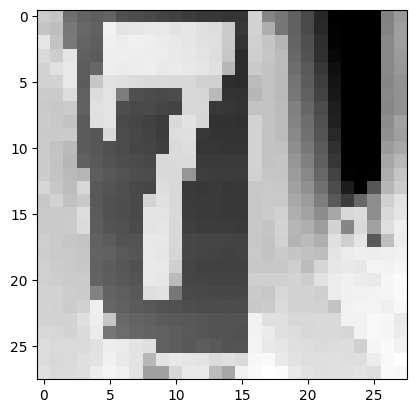

In [193]:
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Error: Could not access the camera.")
    exit()
while True:
    ret, frame = cap.read()
    if not ret:
        print("Failed to capture frame.")
        break

    cv2.imshow("Camera", frame)
    key = cv2.waitKey(1) & 0xFF

    if key == 32:  # SPACE key
        # frame = cv2.flip(frame, 1) 
        img = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        img = cv2.resize(img, (28,28))
        img = 255 - img
        break
    elif key == 27:  # ESC key
        break

cap.release()
cv2.destroyAllWindows()
print(predict(torch.tensor(img,dtype=float32).unsqueeze(0)))
if 'img' in locals():
    plt.imshow(img, cmap="gray")